In [1]:
import os
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

In [2]:
import os
import subprocess

LOCAL_DATA_DIR = "data_deteccion"
os.makedirs(f"{LOCAL_DATA_DIR}/images", exist_ok=True)
os.makedirs(f"{LOCAL_DATA_DIR}/labels", exist_ok=True)

BUCKET = "s3://humanoid-damage-cnn-834257582282-us-east-1-an/processed/damage_classification"

# Sincronizamos imágenes y etiquetas
subprocess.run(["aws", "s3", "sync", f"{BUCKET}/images/", f"{LOCAL_DATA_DIR}/images/", "--quiet"], check=True)
subprocess.run(["aws", "s3", "sync", f"{BUCKET}/labels/", f"{LOCAL_DATA_DIR}/labels/", "--quiet"], check=True)

# Bajamos también classes.txt y data.yaml, ubicados en la raíz de damage_classification/
subprocess.run(["aws", "s3", "cp", f"{BUCKET}/classes.txt", f"{LOCAL_DATA_DIR}/classes.txt", "--quiet"], check=True)
subprocess.run(["aws", "s3", "cp", f"{BUCKET}/data.yaml", f"{LOCAL_DATA_DIR}/data.yaml", "--quiet"], check=True)

# Conteo simple para confirmar que la descarga trajo la misma cantidad de imágenes y labels
n_images = len(os.listdir(f"{LOCAL_DATA_DIR}/images"))
n_labels = len(os.listdir(f"{LOCAL_DATA_DIR}/labels"))
print(f"Imágenes: {n_images} | Labels: {n_labels}")

Imágenes: 6453 | Labels: 6453


In [3]:
import os

# Leemos las clases de classes.txt. El orden importa.
CLASSES_PATH = f"{LOCAL_DATA_DIR}/classes.txt"

with open(CLASSES_PATH) as f:
    CLASS_NAMES = [line.strip() for line in f if line.strip()]

N_CLASSES = len(CLASS_NAMES)
print(f"Clases cargadas desde {CLASSES_PATH}: {N_CLASSES}")
for i, nombre in enumerate(CLASS_NAMES):
    print(f"  {i}: {nombre}")

from collections import Counter
import glob

conteo = Counter()
archivos_con_error = []
ids_inesperados = set()

# Cada archivo .txt de labels/ corresponde a una imagen; cada línea es un daño anotado
for label_path in glob.glob(f"{LOCAL_DATA_DIR}/labels/*.txt"):
    with open(label_path) as f:
        for i, line in enumerate(f):
            line = line.strip()
            if not line:
                continue

            partes = line.split()  # formato: class_id x_center y_center width height

            if len(partes) != 5:
                archivos_con_error.append((label_path, i, "cantidad de valores incorrecta", line))
                continue

            try:
                class_id = int(partes[0])
                xc, yc, w, h = map(float, partes[1:5])
            except ValueError:
                archivos_con_error.append((label_path, i, "valores no numéricos", line))
                continue

            if class_id < 0 or class_id >= N_CLASSES:
                ids_inesperados.add(class_id)
                archivos_con_error.append((label_path, i, f"class_id {class_id} fuera de rango", line))
                continue

            # Las coordenadas YOLO están normalizadas (fracción del ancho/alto), deben estar entre 0 y 1. La ubicación se representa en porcentaje, por ejemplo "el daño se encuentra a 50% de la izquierda" para que funcione en imagenes de distintos tamaños
            if not all(0 <= v <= 1 for v in [xc, yc, w, h]):
                archivos_con_error.append((label_path, i, "coordenadas fuera de rango [0,1]", line))

            conteo[CLASS_NAMES[class_id]] += 1

print("\nConteo de daños por clase:")
for clase, cantidad in conteo.most_common():
    print(f"  {clase}: {cantidad}")

print(f"\nTotal de daños anotados: {sum(conteo.values())}")

if ids_inesperados:
    print(f"\nIDs de clase inesperados encontrados (fuera de 0-{N_CLASSES-1}): {ids_inesperados}")
else:
    print("\nTodos los IDs de clase están dentro del rango esperado")

if archivos_con_error:
    print(f"\nSe encontraron {len(archivos_con_error)} líneas con problemas. Primeras 5:")
    for path, linea_num, motivo, contenido in archivos_con_error[:5]:
        print(f"  {path} (línea {linea_num}): {motivo} → '{contenido}'")
else:
    print("No se encontraron errores de formato en las etiquetas")

Clases cargadas desde data_deteccion/classes.txt: 14
  0: Concrete spalling
  1: Corrosion
  2: Crack
  3: Debris
  4: Detachment crack
  5: Diagonal crack
  6: Flexural/rocking crack
  7: Large displacement
  8: Leaching
  9: Non structural damage
  10: Out-of-plane mechanism
  11: Partial/full collapse
  12: Rebar deformation/buckling
  13: Shear crack

Conteo de daños por clase:
  Diagonal crack: 4490
  Concrete spalling: 4467
  Corrosion: 2927
  Shear crack: 1283
  Flexural/rocking crack: 504
  Non structural damage: 408
  Debris: 307
  Detachment crack: 306
  Crack: 201
  Partial/full collapse: 124
  Leaching: 119
  Rebar deformation/buckling: 42
  Out-of-plane mechanism: 26
  Large displacement: 14

Total de daños anotados: 15218

Todos los IDs de clase están dentro del rango esperado
No se encontraron errores de formato en las etiquetas


In [4]:
import numpy as np

GRID_SIZE = 14  # coincide con la resolución de salida del backbone del modelo 1 (224 -> 14 tras 4 MaxPooling)
DEPTH = 1 + 4 + N_CLASSES  # 1 objectness + 4 coords de la caja + N_CLASSES para el tipo de daño

def parse_label_to_grid(label_path, grid_size=GRID_SIZE, n_classes=N_CLASSES):
    target = np.zeros((grid_size, grid_size, 1 + 4 + n_classes), dtype=np.float32)

    if not os.path.exists(label_path):
        return target  # imagen sin ningún daño anotado, target queda todo en cero

    with open(label_path) as f:
        for line in f:
            partes = line.split()
            class_id = int(partes[0])
            xc, yc, w, h = map(float, partes[1:5])

            # En qué celda de la grilla cae el centro de esta caja
            col = min(int(xc * grid_size), grid_size - 1)
            row = min(int(yc * grid_size), grid_size - 1)

            # Si dos daños caen en la misma celda, nos quedamos con el último (limitación simple)
            target[row, col, 0] = 1.0                     # objectness: hay daño en esta celda
            target[row, col, 1:5] = [xc, yc, w, h]         # coordenadas de la caja
            target[row, col, 5 + class_id] = 1.0           # one-hot de la clase

    return target

In [5]:
# Armamos un array con la cantidad de ejemplos de cada clase, en el mismo orden que CLASS_NAMES
conteo_por_indice = np.array([conteo[nombre] for nombre in CLASS_NAMES], dtype=np.float32)

# Peso inversamente proporcional a la frecuencia (menos ejemplos = más peso),
# suavizado con raíz cuadrada para que el desbalance no sea demasiado extremo
CLASS_WEIGHTS = np.sqrt(1.0 / conteo_por_indice)

# Normalizamos para que el promedio de los pesos sea 1 (referencia central)
CLASS_WEIGHTS = CLASS_WEIGHTS / CLASS_WEIGHTS.mean()

print("Pesos por clase:")
for nombre, peso in zip(CLASS_NAMES, CLASS_WEIGHTS):
    print(f"  {nombre}: {peso:.2f}")

Pesos por clase:
  Concrete spalling: 0.18
  Corrosion: 0.22
  Crack: 0.86
  Debris: 0.69
  Detachment crack: 0.69
  Diagonal crack: 0.18
  Flexural/rocking crack: 0.54
  Large displacement: 3.24
  Leaching: 1.11
  Non structural damage: 0.60
  Out-of-plane mechanism: 2.38
  Partial/full collapse: 1.09
  Rebar deformation/buckling: 1.87
  Shear crack: 0.34


In [6]:
import glob

image_files = sorted(glob.glob(f"{LOCAL_DATA_DIR}/images/*.jpg"))

def get_label_path(image_path):
    return image_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"

def repeticiones_por_rareza(label_path):
    """Cuántas veces repetir esta imagen en el dataset, según la clase más rara que contenga."""
    if not os.path.exists(label_path):
        return 1
    max_peso = 1.0
    with open(label_path) as f:
        for line in f:
            class_id = int(line.split()[0])
            max_peso = max(max_peso, CLASS_WEIGHTS[class_id])
    return max(1, round(max_peso))

# Split 80/20 sobre las imágenes originales antes del sobremuestreo.
# Esto evita que copias de una misma imagen terminen en train y validation.
import random

RANDOM_SEED = 42
TRAIN_RATIO = 0.8

random.seed(RANDOM_SEED)
image_files_shuffled = list(image_files)
random.shuffle(image_files_shuffled)

n_total_original = len(image_files_shuffled)
n_train_original = int(n_total_original * TRAIN_RATIO)
train_original_paths = image_files_shuffled[:n_train_original]
val_paths = image_files_shuffled[n_train_original:]

# Aplicamos sobremuestreo solo al subconjunto de entrenamiento.
train_paths = []
for img_path in train_original_paths:
    n_rep = repeticiones_por_rareza(get_label_path(img_path))
    train_paths.extend([img_path] * n_rep)

overlap = set(train_paths) & set(val_paths)
assert len(overlap) == 0, f"DATA LEAKAGE: {len(overlap)} imágenes aparecen en train y validation"

print(f"Imágenes originales: {len(image_files)}")
print(f"Train original: {len(train_original_paths)} | Train tras sobremuestreo: {len(train_paths)}")
print(f"Validation sin sobremuestreo: {len(val_paths)}")
print(f"Overlap train/validation: {len(overlap)}")

Imágenes originales: 6453
Train original: 5162 | Train tras sobremuestreo: 5235
Validation sin sobremuestreo: 1291
Overlap train/validation: 0


In [7]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 80
LEARNING_RATE = 1e-4
CHECKPOINT_PATH = "../models/best_detector.keras"
RUN_TRAINING = True  # Cambiar a True solo cuando se quiera iniciar model.fit() explícitamente

def load_sample(image_path):
    image_path = image_path.numpy().decode("utf-8")
    label_path = image_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"

    img = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)

    target = parse_label_to_grid(label_path)
    return img_array, target

def tf_load_sample(image_path):
    img, target = tf.py_function(load_sample, [image_path], [tf.float32, tf.float32])
    img.set_shape([224, 224, 3])
    target.set_shape([GRID_SIZE, GRID_SIZE, 1 + 4 + N_CLASSES])
    return img, target

train_ds = tf.data.Dataset.from_tensor_slices(train_paths).map(
    tf_load_sample, num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices(val_paths).map(
    tf_load_sample, num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Datasets armados")

I0000 00:00:1786304839.648193    5212 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Datasets armados


W0000 00:00:1786304845.507393    5212 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1786304845.507635    5212 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2244 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5


In [8]:
print("GPUs detectadas:", tf.config.list_physical_devices('GPU'))

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [9]:
modelo1 = tf.keras.models.load_model("../models/best_model.keras")

# Buscamos la última capa MaxPooling2D del modelo 1 (fin del backbone puro,
# antes de GlobalAveragePooling, Dense, y también antes del data_augmentation
# que solo aplica durante el entrenamiento del modelo 1)
backbone_output = None
for layer in modelo1.layers:
    if isinstance(layer, tf.keras.layers.MaxPooling2D):
        backbone_output = layer.output

assert backbone_output is not None, "No se encontró ninguna capa MaxPooling2D en modelo1"

backbone = tf.keras.Model(inputs=modelo1.input, outputs=backbone_output, name="backbone_reutilizado")
backbone.trainable = False  # arranca congelado, se descongela en la Fase 2 del entrenamiento

print("Backbone reutilizado, forma de salida:", backbone.output_shape)

Backbone reutilizado, forma de salida: (None, 14, 14, 256)


In [10]:
for layer in modelo1.layers[:5]:
    print(layer.name, type(layer).__name__)

input_layer InputLayer
rescaling Rescaling
sequential Sequential
conv2d Conv2D
batch_normalization BatchNormalization


In [11]:
from tensorflow.keras import layers

x = backbone.output  # (14, 14, 256)

x = layers.Conv2D(256, 3, padding="same", activation="relu", name="det_conv2d_1")(x)
x = layers.Conv2D(128, 3, padding="same", activation="relu", name="det_conv2d_2")(x)

depth = 1 + 4 + N_CLASSES  # objectness + 4 coords caja + clases

# Inicializamos el bias del canal de objectness con la frecuencia real de celdas positivas,
# para que el modelo arranque cerca de la distribución real en vez de arrancar en 50/50
frac_positivas = 0.0115  # calculado antes con sample_targets
bias_inicial_objectness = np.log(frac_positivas / (1 - frac_positivas))
bias_init = np.zeros(depth, dtype=np.float32)
bias_init[0] = bias_inicial_objectness

output = layers.Conv2D(
    depth, 1, padding="same", activation="linear", name="det_output",
    bias_initializer=tf.keras.initializers.Constant(bias_init)
)(x)

modelo_deteccion = tf.keras.Model(inputs=backbone.input, outputs=output, name="modelo_deteccion")
modelo_deteccion.summary()

Model: "modelo_deteccion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ det_conv2d_1 (Conv2D)           │ (None, 14, 14, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ det_conv2d_2 (Conv2D)           │ (None, 14, 14, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ det_output (Conv2D)             │ (None, 14, 14, 19)     │         2,451 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,277,907 (4.87 MB)

 Trainable params: 887,571 (3.39 MB)

 Non-trainable params: 390,336 (1.49 MB)

In [12]:
CLASS_WEIGHTS_TF = tf.constant(CLASS_WEIGHTS, dtype=tf.float32)

def focal_loss_objectness(y_true, y_pred_logits, alpha=0.25, gamma=2.0):
    p = tf.sigmoid(y_pred_logits)
    ce = tf.nn.sigmoid_cross_entropy_with_logits(labels=y_true, logits=y_pred_logits)
    p_t = y_true * p + (1 - y_true) * (1 - p)
    alpha_t = y_true * alpha + (1 - y_true) * (1 - alpha)
    return alpha_t * tf.pow(1.0 - p_t, gamma) * ce

def detection_loss(y_true, y_pred, lambda_coord=5.0):
    obj_mask = y_true[..., 0]
    obj_true = y_true[..., 0]
    obj_logits = y_pred[..., 0]
    loss_obj = focal_loss_objectness(obj_true, obj_logits)

    box_true = y_true[..., 1:5]
    box_pred = y_pred[..., 1:5]
    xy_true, wh_true = box_true[..., :2], box_true[..., 2:]
    xy_pred, wh_pred = box_pred[..., :2], box_pred[..., 2:]
    loss_xy = tf.reduce_sum(tf.square(xy_true - xy_pred), axis=-1)
    loss_wh = tf.reduce_sum(tf.square(tf.sqrt(tf.maximum(wh_true, 1e-6)) - tf.sqrt(tf.maximum(wh_pred, 1e-6))), axis=-1)
    loss_box = obj_mask * (loss_xy + loss_wh)

    class_true = y_true[..., 5:]
    class_pred = tf.nn.softmax(y_pred[..., 5:], axis=-1)
    loss_class = tf.keras.losses.categorical_crossentropy(class_true, class_pred)
    peso_clase = tf.reduce_sum(class_true * CLASS_WEIGHTS_TF, axis=-1)
    loss_class = obj_mask * peso_clase * loss_class

    total = tf.reduce_mean(loss_obj) + lambda_coord * tf.reduce_mean(loss_box) + tf.reduce_mean(loss_class)
    return total

In [13]:
modelo_deteccion.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=detection_loss
)

### Preparación previa al entrenamiento

Las siguientes celdas dejan listo el entrenamiento local. Para iniciar `modelo_deteccion.fit(...)`, cambiar `RUN_TRAINING = True` y ejecutar la celda de entrenamiento manual.

In [14]:
sample_images, sample_targets = next(iter(train_ds))
expected_output_shape = tuple(modelo_deteccion.output_shape[1:])
actual_target_shape = tuple(sample_targets.shape[1:])

print("Batch imágenes:", sample_images.shape)
print("Batch targets:", sample_targets.shape)
print("Salida del modelo:", modelo_deteccion.output_shape)

assert actual_target_shape == expected_output_shape, (
    f"Targets incompatibles con la salida del modelo: {actual_target_shape} != {expected_output_shape}"
)

sample_predictions = modelo_deteccion(sample_images[:1], training=False)
assert tuple(sample_predictions.shape[1:]) == expected_output_shape
print("Verificación OK: train_ds entrega targets compatibles con detection_loss y modelo_deteccion.")

Batch imágenes: (16, 224, 224, 3)
Batch targets: (16, 14, 14, 19)
Salida del modelo: (None, 14, 14, 19)


I0000 00:00:1786304847.893338    5212 cuda_dnn.cc:461] Loaded cuDNN version 92400


Verificación OK: train_ds entrega targets compatibles con detection_loss y modelo_deteccion.


In [15]:
os.makedirs("../models", exist_ok=True)

In [16]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        CHECKPOINT_PATH,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        verbose=1,
    ),
]

print(f"Callbacks preparados. El mejor detector se guardará en: {CHECKPOINT_PATH}")

Callbacks preparados. El mejor detector se guardará en: ../models/best_detector.keras


### Entrenamiento manual

La siguiente celda contiene `model.fit(...)`, pero solo lo ejecuta si `RUN_TRAINING = True`. Al activarla, consume CPU/GPU y puede generar el checkpoint `../models/best_detector.keras`.

In [17]:
if not RUN_TRAINING:
    print("Entrenamiento preparado pero no iniciado. Cambiar RUN_TRAINING = True para ejecutar model.fit().")
else:
    def crear_callbacks():
        return [
            tf.keras.callbacks.ModelCheckpoint(
                CHECKPOINT_PATH,
                monitor="val_loss",
                mode="min",
                save_best_only=True,
                verbose=1,
            ),
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True,
                verbose=1,
            ),
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=4,
                verbose=1,
            ),
        ]

    print("=== Fase 1: warm-up de la cabeza (backbone congelado) ===")
    history_warmup = modelo_deteccion.fit(
        train_ds,
        validation_data=val_ds,
        epochs=5,
        callbacks=crear_callbacks(),
        verbose=1,
    )

    print("=== Fase 2: fine-tuning completo (backbone descongelado) ===")
    backbone.trainable = True
    modelo_deteccion.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE / 10),
        loss=detection_loss,
    )
    history = modelo_deteccion.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=crear_callbacks(),
        verbose=1,
    )

=== Fase 1: warm-up de la cabeza (backbone congelado) ===
Epoch 1/5


/home/bachi/proyectos/humanoid-damage-cnn/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


328/328 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - loss: 0.0400
Epoch 1: val_loss improved from None to 0.04025, saving model to ../models/best_detector.keras

Epoch 1: finished saving model to ../models/best_detector.keras
328/328 ━━━━━━━━━━━━━━━━━━━━ 80s 228ms/step - loss: 0.0400 - val_loss: 0.0402 - learning_rate: 1.0000e-04
Epoch 2/5
327/328 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - loss: 0.0305
Epoch 2: val_loss improved from 0.04025 to 0.03021, saving model to ../models/best_detector.keras

Epoch 2: finished saving model to ../models/best_detector.keras
328/328 ━━━━━━━━━━━━━━━━━━━━ 72s 218ms/step - loss: 0.0305 - val_loss: 0.0302 - learning_rate: 1.0000e-04
Epoch 3/5
327/328 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - loss: 0.0272
Epoch 3: val_loss improved from 0.03021 to 0.02743, saving model to ../models/best_detector.keras

Epoch 3: finished saving model to ../models/best_detector.keras
328/328 ━━━━━━━━━━━━━━━━━━━━ 72s 219ms/step - loss: 0.0272 - val_loss: 0.0274 - learning_rate: 1.0000e-04
Ep

In [18]:
if "history" not in globals():
    print("Todavía no hay history: ejecutar primero el entrenamiento.")
else:
    val_results = modelo_deteccion.evaluate(val_ds, verbose=1)
    print("Resultados en validation:", val_results)

81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 172ms/step - loss: 0.0219
Resultados en validation: 0.02190757915377617


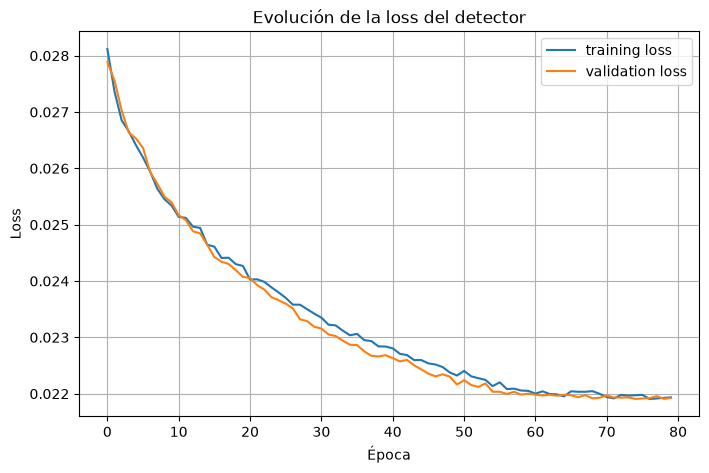

In [19]:
if "history" not in globals():
    print("Todavía no hay history: ejecutar primero la celda de entrenamiento.")
else:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(8, 5))
    plt.plot(history.history.get("loss", []), label="training loss")
    plt.plot(history.history.get("val_loss", []), label="validation loss")
    plt.xlabel("Época")
    plt.ylabel("Loss")
    plt.title("Evolución de la loss del detector")
    plt.legend()
    plt.grid(True)
    plt.show()

In [20]:
if os.path.exists(CHECKPOINT_PATH):
    best_detector = tf.keras.models.load_model(
        CHECKPOINT_PATH,
        custom_objects={"detection_loss": detection_loss},
    )
    print(f"Mejor detector cargado desde: {CHECKPOINT_PATH}")
else:
    print(f"Aún no existe checkpoint en: {CHECKPOINT_PATH}")

Mejor detector cargado desde: ../models/best_detector.keras


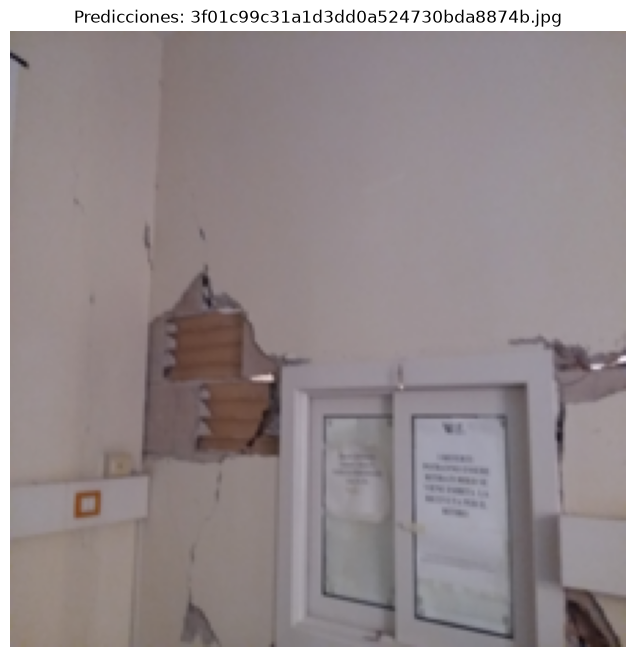

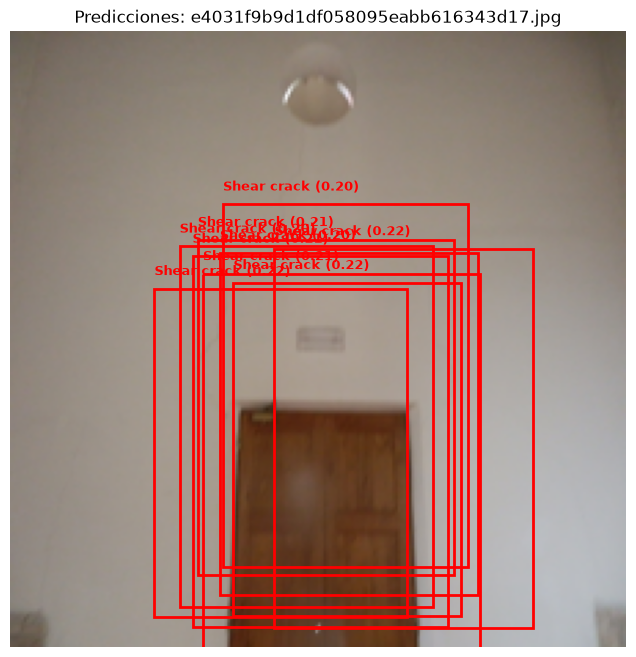

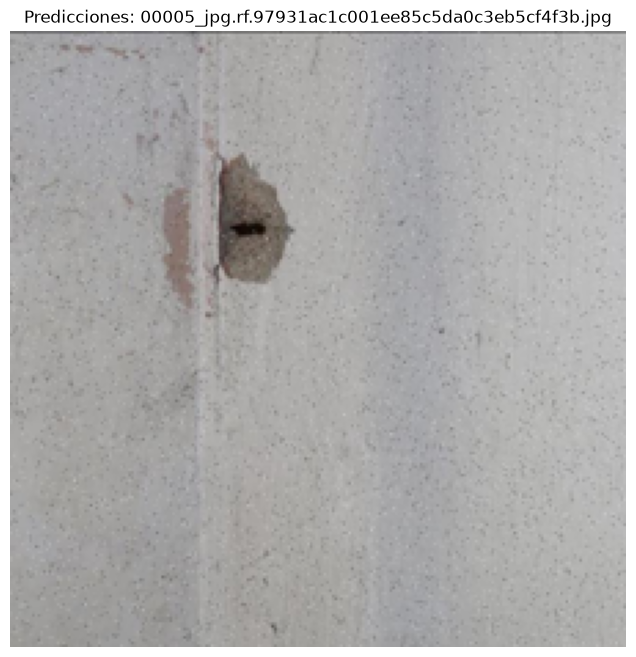

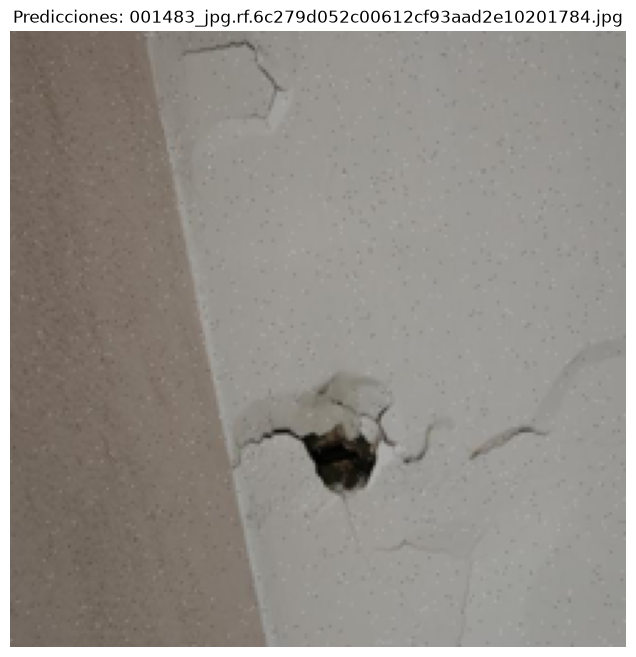

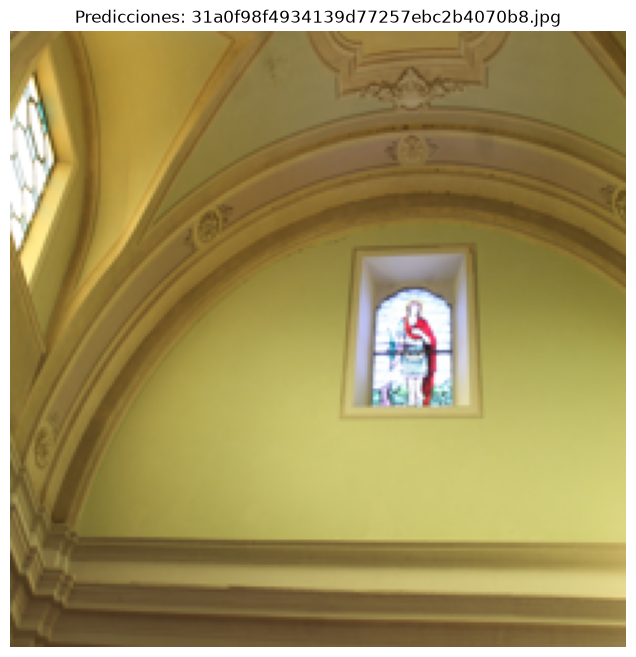

In [21]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

def dibujar_predicciones(modelo, image_path, grid_size=GRID_SIZE, n_classes=N_CLASSES,
                          umbral_objectness=0.5, img_size=IMG_SIZE):
    img = Image.open(image_path).convert("RGB").resize(img_size)
    img_array = tf.keras.utils.img_to_array(img)
    pred = modelo(tf.expand_dims(img_array, 0), training=False)[0]  # (14, 14, depth)

    fig, ax = plt.subplots(1, figsize=(8, 8))
    ax.imshow(img)

    for row in range(grid_size):
        for col in range(grid_size):
            objectness = tf.sigmoid(pred[row, col, 0]).numpy()
            if objectness < umbral_objectness:
                continue

            xc, yc, w, h = pred[row, col, 1:5].numpy()
            class_probs = tf.nn.softmax(pred[row, col, 5:]).numpy()
            class_id = class_probs.argmax()

            # Convertir de coordenadas normalizadas (0-1) a píxeles
            x_px = (xc - w / 2) * img_size[0]
            y_px = (yc - h / 2) * img_size[1]
            w_px = w * img_size[0]
            h_px = h * img_size[1]

            rect = patches.Rectangle((x_px, y_px), w_px, h_px,
                                      linewidth=2, edgecolor="red", facecolor="none")
            ax.add_patch(rect)
            ax.text(x_px, y_px - 5, f"{CLASS_NAMES[class_id]} ({objectness:.2f})",
                     color="red", fontsize=9, weight="bold")

    ax.set_title(f"Predicciones: {os.path.basename(image_path)}")
    plt.axis("off")
    plt.show()

# Probamos con algunas imágenes de validation
for path in val_paths[:5]:
    dibujar_predicciones(best_detector, path, umbral_objectness=0.2)

In [22]:
img = Image.open(val_paths[0]).convert("RGB").resize(IMG_SIZE)
img_array = tf.keras.utils.img_to_array(img)
pred = best_detector(tf.expand_dims(img_array, 0), training=False)[0]

objectness_scores = tf.sigmoid(pred[..., 0]).numpy()
print("Máximo objectness en toda la grilla:", objectness_scores.max())
print("Promedio:", objectness_scores.mean())

Máximo objectness en toda la grilla: 0.16880503
Promedio: 0.101449676


In [23]:
sample_images, sample_targets = next(iter(train_ds))
frac_positivas = (sample_targets[..., 0] == 1).numpy().mean()
print(f"Fracción de celdas con objeto en un batch: {frac_positivas:.4f}")
print(f"O sea, aprox {frac_positivas * GRID_SIZE * GRID_SIZE:.1f} celdas positivas de {GRID_SIZE*GRID_SIZE} totales, por imagen")

Fracción de celdas con objeto en un batch: 0.0115
O sea, aprox 2.2 celdas positivas de 196 totales, por imagen


In [24]:
def non_max_suppression(predicciones, umbral_iou_nms=0.4):
    resultado = []
    clases_presentes = set(p[4] for p in predicciones)
    for clase in clases_presentes:
        preds_clase = [p for p in predicciones if p[4] == clase]
        preds_clase = sorted(preds_clase, key=lambda p: p[5], reverse=True)
        while preds_clase:
            mejor = preds_clase.pop(0)
            resultado.append(mejor)
            preds_clase = [p for p in preds_clase if calcular_iou(mejor[:4], p[:4]) < umbral_iou_nms]
    return resultado

def calcular_iou(box1, box2):
    """box format: (xc, yc, w, h) normalizado 0-1"""
    x1_min, y1_min = box1[0] - box1[2]/2, box1[1] - box1[3]/2
    x1_max, y1_max = box1[0] + box1[2]/2, box1[1] + box1[3]/2
    x2_min, y2_min = box2[0] - box2[2]/2, box2[1] - box2[3]/2
    x2_max, y2_max = box2[0] + box2[2]/2, box2[1] + box2[3]/2

    inter_xmin = max(x1_min, x2_min)
    inter_ymin = max(y1_min, y2_min)
    inter_xmax = min(x1_max, x2_max)
    inter_ymax = min(y1_max, y2_max)

    inter_area = max(0, inter_xmax - inter_xmin) * max(0, inter_ymax - inter_ymin)
    area1 = box1[2] * box1[3]
    area2 = box2[2] * box2[3]
    union_area = area1 + area2 - inter_area

    return inter_area / union_area if union_area > 0 else 0.0


def evaluar_deteccion(modelo, paths, umbral_objectness=0.5, umbral_iou=0.5):
    total_predicciones = 0
    total_reales = 0
    verdaderos_positivos = 0
    ious_matched = []

    for image_path in paths:
        img = Image.open(image_path).convert("RGB").resize(IMG_SIZE)
        img_array = tf.keras.utils.img_to_array(img)
        pred = modelo(tf.expand_dims(img_array, 0), training=False)[0]

        # Predicciones del modelo
        predicciones = []
        for row in range(GRID_SIZE):
            for col in range(GRID_SIZE):
                objectness = tf.sigmoid(pred[row, col, 0]).numpy()
                if objectness < umbral_objectness:
                    continue
                xc, yc, w, h = pred[row, col, 1:5].numpy()
                class_id = tf.nn.softmax(pred[row, col, 5:]).numpy().argmax()
                predicciones.append((xc, yc, w, h, class_id, objectness))

        predicciones = non_max_suppression(predicciones)

        # Cajas reales, leídas directo del label
        label_path = get_label_path(image_path)
        reales = []
        if os.path.exists(label_path):
            with open(label_path) as f:
                for line in f:
                    partes = line.split()
                    class_id = int(partes[0])
                    xc, yc, w, h = map(float, partes[1:5])
                    reales.append((xc, yc, w, h, class_id))

        total_predicciones += len(predicciones)
        total_reales += len(reales)

        usados = set()
        for pred_box in predicciones:
            mejor_iou = 0
            mejor_idx = -1
            for idx, real_box in enumerate(reales):
                if idx in usados:
                    continue
                iou = calcular_iou(pred_box[:4], real_box[:4])
                if iou > mejor_iou:
                    mejor_iou = iou
                    mejor_idx = idx
            if mejor_iou >= umbral_iou:
                verdaderos_positivos += 1
                ious_matched.append(mejor_iou)
                usados.add(mejor_idx)

    precision = verdaderos_positivos / total_predicciones if total_predicciones > 0 else 0.0
    recall = verdaderos_positivos / total_reales if total_reales > 0 else 0.0
    iou_promedio = np.mean(ious_matched) if ious_matched else 0.0

    print(f"Total predicciones: {total_predicciones}")
    print(f"Total daños reales: {total_reales}")
    print(f"Verdaderos positivos (IoU >= {umbral_iou}): {verdaderos_positivos}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"IoU promedio (en detecciones correctas): {iou_promedio:.3f}")

    return precision, recall, iou_promedio


evaluar_deteccion(best_detector, val_paths, umbral_objectness=0.3)

Total predicciones: 102
Total daños reales: 3051
Verdaderos positivos (IoU >= 0.5): 1
Precision: 0.010
Recall: 0.000
IoU promedio (en detecciones correctas): 0.666


(0.00980392156862745, 0.00032776138970829236, np.float32(0.6657455))

In [ ]:
for umbral in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    print(f"\n--- Umbral objectness: {umbral} ---")
    evaluar_deteccion(best_detector, val_paths, umbral_objectness=umbral)


--- Umbral objectness: 0.2 ---
